In [39]:
from pathlib import Path

from PIL import Image
import torch
import numpy as np

from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision.transforms.functional import to_tensor

class ImageDirectoryDataset(Dataset):
    EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}

    def __init__(self, directory):
        root = Path(directory).expanduser()
        if not root.is_dir():
            raise NotADirectoryError(root)

        # Sorting makes label assignments reproducible.
        class_dirs = sorted(
            (p for p in root.iterdir() if p.is_dir()),
            key=lambda p: p.name,
        )
        self.classes = [p.name for p in class_dirs]
        self.class_to_idx = {
            name: index for index, name in enumerate(self.classes)
        }

        self.samples = [
            (path, self.class_to_idx[class_dir.name])
            for class_dir in class_dirs
            for path in sorted(class_dir.rglob("*"))
            if path.is_file() and path.suffix.lower() in self.EXTENSIONS
        ]

        if not self.samples:
            raise ValueError(f"No images found in class subdirectories of {root}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as image:
            # if we had color data, we would use this line instead of plain to_tensor:
            #image = to_tensor(image.convert("RGB"))
            image = to_tensor(image)
        return image, label

In [40]:
train_ds = ImageDirectoryDataset("./data/binary-mnist/train")
test_ds = ImageDirectoryDataset("./data/binary-mnist/test")

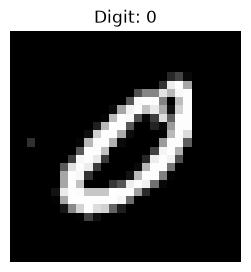

In [41]:
image, label = train_ds[0]
plt.figure(figsize=(3, 3))
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Digit: {label}")
plt.axis("off")
plt.show()

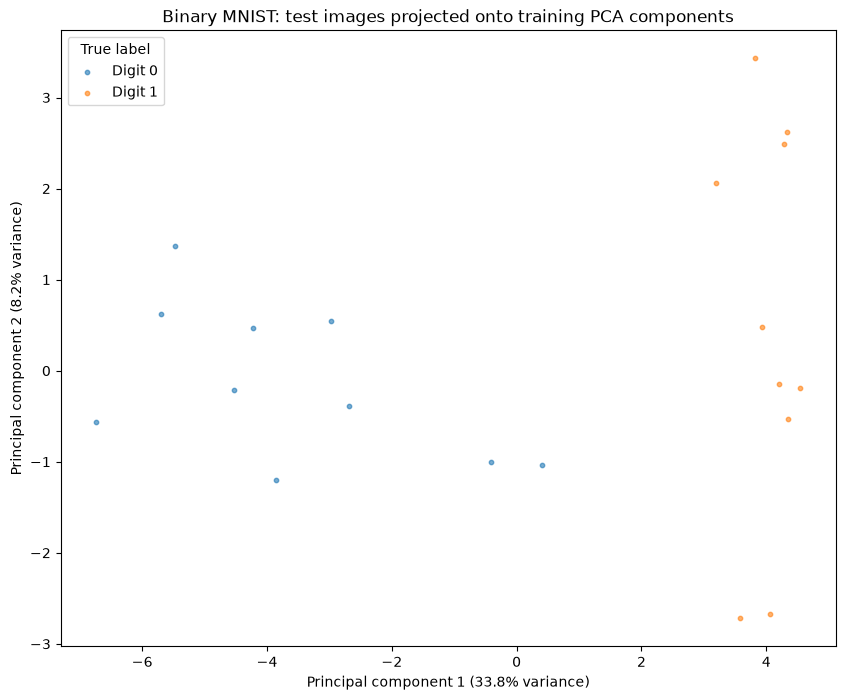

In [42]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from sklearn.decomposition import PCA

# Project the images into 2D without training a classifier.
# DataLoader respects the selected subset and its image transforms.
train_images = torch.cat([
    images.flatten(start_dim=1)
    for images, _ in DataLoader(train_ds, batch_size=512, shuffle=False)
]).numpy()
test_batches = list(DataLoader(test_ds, batch_size=512, shuffle=False))
test_images = torch.cat([images.flatten(start_dim=1) for images, _ in test_batches]).numpy()
labels = torch.cat([labels for _, labels in test_batches]).numpy()

pca = PCA(n_components=2, svd_solver="randomized", random_state=0)
pca.fit(train_images)
points = pca.transform(test_images)

fig, ax = plt.subplots(figsize=(10, 8))
for digit in np.unique(labels):
    mask = labels == digit
    ax.scatter(points[mask, 0], points[mask, 1], s=10, alpha=0.6,
               label=f"Digit {digit}")
ax.set(
    xlabel=f"Principal component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
    ylabel=f"Principal component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)",
    title="Binary MNIST: test images projected onto training PCA components",
)
ax.legend(title="True label")
plt.show()